## CA1 Machine Learning for Business

#### Name: Mayra Alejandra Lugo Caicedo
#### Code: 2026119

Assement
1. A precise introduction, motivation, description of problem domain, Assessment objectives and the rationale for the chosen dataset in the above-mentioned areas.
2. Which clustering algorithms would you consider for segmentation, and why? Implement the solutions and discuss the differences between silhouette score and Davies-Bouldin index in the context of clustering. Compare the results obtained from any two clustering algorithms from your own chosen dataset.
3. Implement your solutions and discuss what insights can you derive from the initial exploration of the time series data based on the provided topics? Describe any trends, seasonality, or anomalies observed. How did you determine the appropriate parameters (p, d, q) for the ARIMA/ SARIMA model. Evaluate the performance of the ARIMA/ SARIMA model in forecasting future values, highlighting any strengths and limitations based on your chosen dataset.

## 1. Business understanding

### 1.1 Introduction:

At present investing has been the recommendation by the experts to grow money, according to BBVA Bank invest is the process of pursaching assets increase in value over time and it provides returns in the form of income payments or capital gains (BBVA, n.d.). Investing in the stock market has become one of the most popular ways to icrease the net worth, being a place where buyers and sellers come together to trade shares and other financial assets both fixed-income and equity-based (bonds, whether government or corporate, or ETFs, exchange-traded funds, amongst other securities)(BBVA, n.d.), Currently, individuals and companies are looking for the best strategies to increase their net worth. Technological tools such as machine learning has been sucessful due to their prediction nature helping professionals to make better desicion at the moment of buying  or selling in the stock market. 

An Exchange-traded funds (ETFs) is a popular type of collective investment that provide access to a wide range of markets, one of the most popular (ETFs) is The Invesco QQQ an ETF that offers exposure to many of the companies driving innovation across technology, consumer services, healthcare, and other growth-oriented sectors.(Invesco, 2026) this project will apply a machine Learning techniques of clustering and time series (Arima/Sarima) to the  ETF QQQ to segment the  days by behavior of the stock market and predict  futute prices.

### 1.2 Problem the domain: 

### 1.3 Motivation:

### 1.4 Objetives:

## 2. Data Understanding

### 2.1 Loading the data

To carry out this project, it is necessary to import all the libraries and load the data in this case, the last 10 years for the QQQ ETF. All the data has been dowloaded by yahoo finances 

In [1]:
#Import all the libraries required to develop the project 
import numpy as np
import pandas as pd
import seaborn as sns
import statistics as st
import matplotlib.pyplot as plt
import re
import unicodedata
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.decomposition import PCA
sns.set(color_codes=True)
sns.set(style="whitegrid")
import yfinance as yf
import os

In [2]:
#Import warnings and ommit it 
import warnings
warnings.filterwarnings('ignore')

In [3]:
# Define the ticker symbol for QQQ (QQQ)
ticker_symbol = "QQQ"
start_date="2016-10-10"
end_date="2026-10-09"
csv_path="QQQ_10years.csv"

In [4]:

# Download historical data (adjust the period as needed, e.g., '1mo', '1y', 'max')
data = yf.download("QQQ", start="2016-10-10", end="2026-10-09", auto_adjust=False) 
#clean the MultiIndex
if isinstance (data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)
#Dropping the rowsthat are creating a blank space
data = data.dropna(subset=['Close', 'Adj Close'])
# Save the data to a CSV file
data.to_csv('QQQ_10years.csv')
print(f"Dataset 10 years")

[*********************100%***********************]  1 of 1 completed

Dataset 10 years


I create a new varible called df_QQQ and load the dataset using the funtion from pandas pd.read_csv.

In [5]:
#Loading the file 
df_QQQ = pd.read_csv("QQQ_10years.csv")

I apply .shape to get the dimentions of the data

In [6]:
#Getting the dimentions of the dataset
df_QQQ.shape

(2513, 7)

The DataSet cointains 2704 rows and 7 columns wich have features of date, Adj Close, Close, High, Low, Open and Volumen.

In [7]:
#verifying the load of the data set
df_QQQ.head()

,Date,Adj Close,Close,High,Low,Open,Volume
0,2016-10-10,111.411179,119.220001,119.480003,119.029999,119.080002,19687300
1,2016-10-11,109.822517,117.519997,119.139999,117.000000,119.120003,27774400
2,2016-10-12,109.729088,117.419998,117.820000,117.059998,117.629997,14267800
3,2016-10-13,109.336594,117.000000,117.320000,115.940002,116.620003,22821000
4,2016-10-14,109.467422,117.139999,118.050003,117.070000,117.580002,21313300


After applying .head(), I can check whe the data load correctly, dates have the correct format and the values makes sense

In [8]:
#I use .info() to obtain a summary of the Data frame, including names, data types and non-null counts.
df_QQQ.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2513 entries, 0 to 2512
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2513 non-null   object 
 1   Adj Close  2513 non-null   float64
 2   Close      2513 non-null   float64
 3   High       2513 non-null   float64
 4   Low        2513 non-null   float64
 5   Open       2513 non-null   float64
 6   Volume     2513 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 137.6+ KB


After applying the funtion .info() I can check the names of the columns, the null values in this case data it is not showing null/Nan values and finally the Dtype, the last one is showing that the variable Date is an Object, it means that the variable will have process  before training the models

### 2.2 EDA

#### 2.2.1 Descriptive Statistics

After understanding the dtype of each feature it is important to examine the characteristic of the data, as distribution, unusual values and potential issues. For this purpose, I will analyse the variables numericals doing a univariable analysis and bivariate analysis.

#### 2.2.2 Distributions

##### Univariable Analysis

I evaluate each variable; this analysis is conducted to understand the distribution of each variable and their behavior.To analyse the numerical variables('Adj Close', 'Close', 'High', 'Low', 'Open' and 'Volumen'), I use histogram to see the centre, symmetric shaped and spread of dataset I used. Hist to get the information:

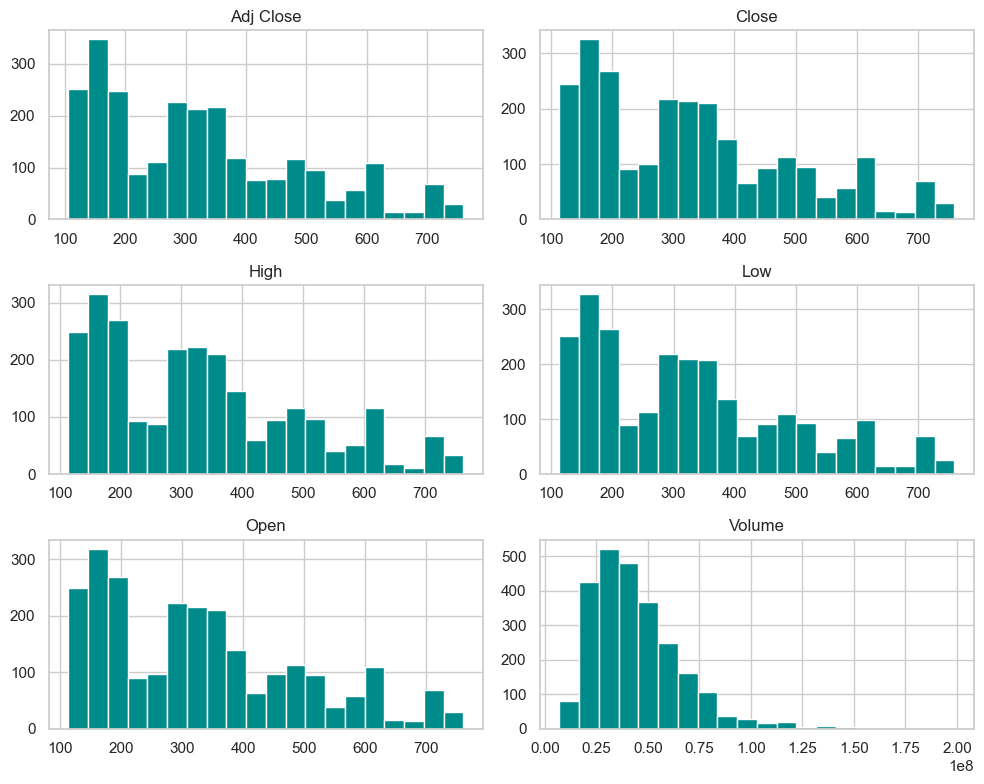

In [9]:
# Univariable Analysis - Numerical Variables.
df_QQQ.hist(figsize=(10,8), bins=20, color="darkcyan")
plt.tight_layout()
plt.show()

***Symmetry***

Based on the descriptive table and histograms:

Adj Close -The varible Adj Close ranges from 106.20 to 759.65 with a median in 300.35. The distribution is slightly left-skewed, suggesting that more observations are concentrate after 1980. The graphic shows a multimodal pattern with three after 1990.

Close - The varible Matched VEI is a discrete scale from 0 to 6. The most common value is VEI is 2 ("moderate event") followed by VEI 3. The distribution is right-skewed, indicating that most eruptions in the dataset are moderate (VEI 2-3), however, the graphic demostrated a right tail of the distribution contains rare but valid VEI 5 and 6 events.

High - The varible Matched VEI is a discrete scale from 0 to 6. The most common value is VEI is 2 ("moderate event") followed by VEI 3. The distribution is right-skewed, indicating that most eruptions in the dataset are moderate (VEI 2-3), however, the graphic demostrated a right tail of the distribution contains rare but valid VEI 5 and 6 events.The variable gdp_per_capita (GDP per person, in US$) ranges from 74.098811 to 42872.268124 with a median in 2162.913759. The distribution is strongly right-skewd, suggesting that more eruptions happen in low income countries, with some exceptions of high income.

Low - The varible Matched VEI is a discrete scale from 0 to 6. The most common value is VEI is 2 ("moderate event") followed by VEI 3. The distribution is right-skewed, indicating that most eruptions in the dataset are moderate (VEI 2-3), however, the graphic demostrated a right tail of the distribution contains rare but valid VEI 5 and 6 events.The varible governance_avg is the average of 6 index of the world Bank WGI the ranges of this are from -1.226691 to 1.794540 with a median in -0.403917. The distribution is right-skewed, The graphic shows a roughly unimodal pattern with a long right tail, reflecting the global distribution of volcanic activity.

Open - The varible Matched VEI is a discrete scale from 0 to 6. The most common value is VEI is 2 ("moderate event") followed by VEI 3. The distribution is right-skewed, indicating that most eruptions in the dataset are moderate (VEI 2-3), however, the graphic demostrated a right tail of the distribution contains rare but valid VEI 5 and 6 events.Target The varible Total affect ranges from 24 to over 1.500.000 people, with a median 8500 of and a mean of 50376.The distribution is stronfly right-skwed. this indicates tahta most eruptions in the dataset affected a relatively small number of people.

Volumen  - The varible Matched VEI is a discrete scale from 0 to 6. The most common value is VEI is 2 ("moderate event") followed by VEI 3. The distribution is right-skewed, indicating that most eruptions in the dataset are moderate (VEI 2-3), however, the graphic demostrated a right tail of the distribution contains rare but valid VEI 5 and 6 events.Target The varible Total affect ranges from 24 to over 1.500.000 people, with a median 8500 of and a mean of 50376.The distribution is stronfly right-skwed. this indicates tahta most eruptions in the dataset affected a relatively small number of people.

#### 2.2.3 Outliers

To analyse the number of outliers per category, I apply sns.boxplot to get a illustration of a boxplot per each one, in general the data does not have a big number of outliers.

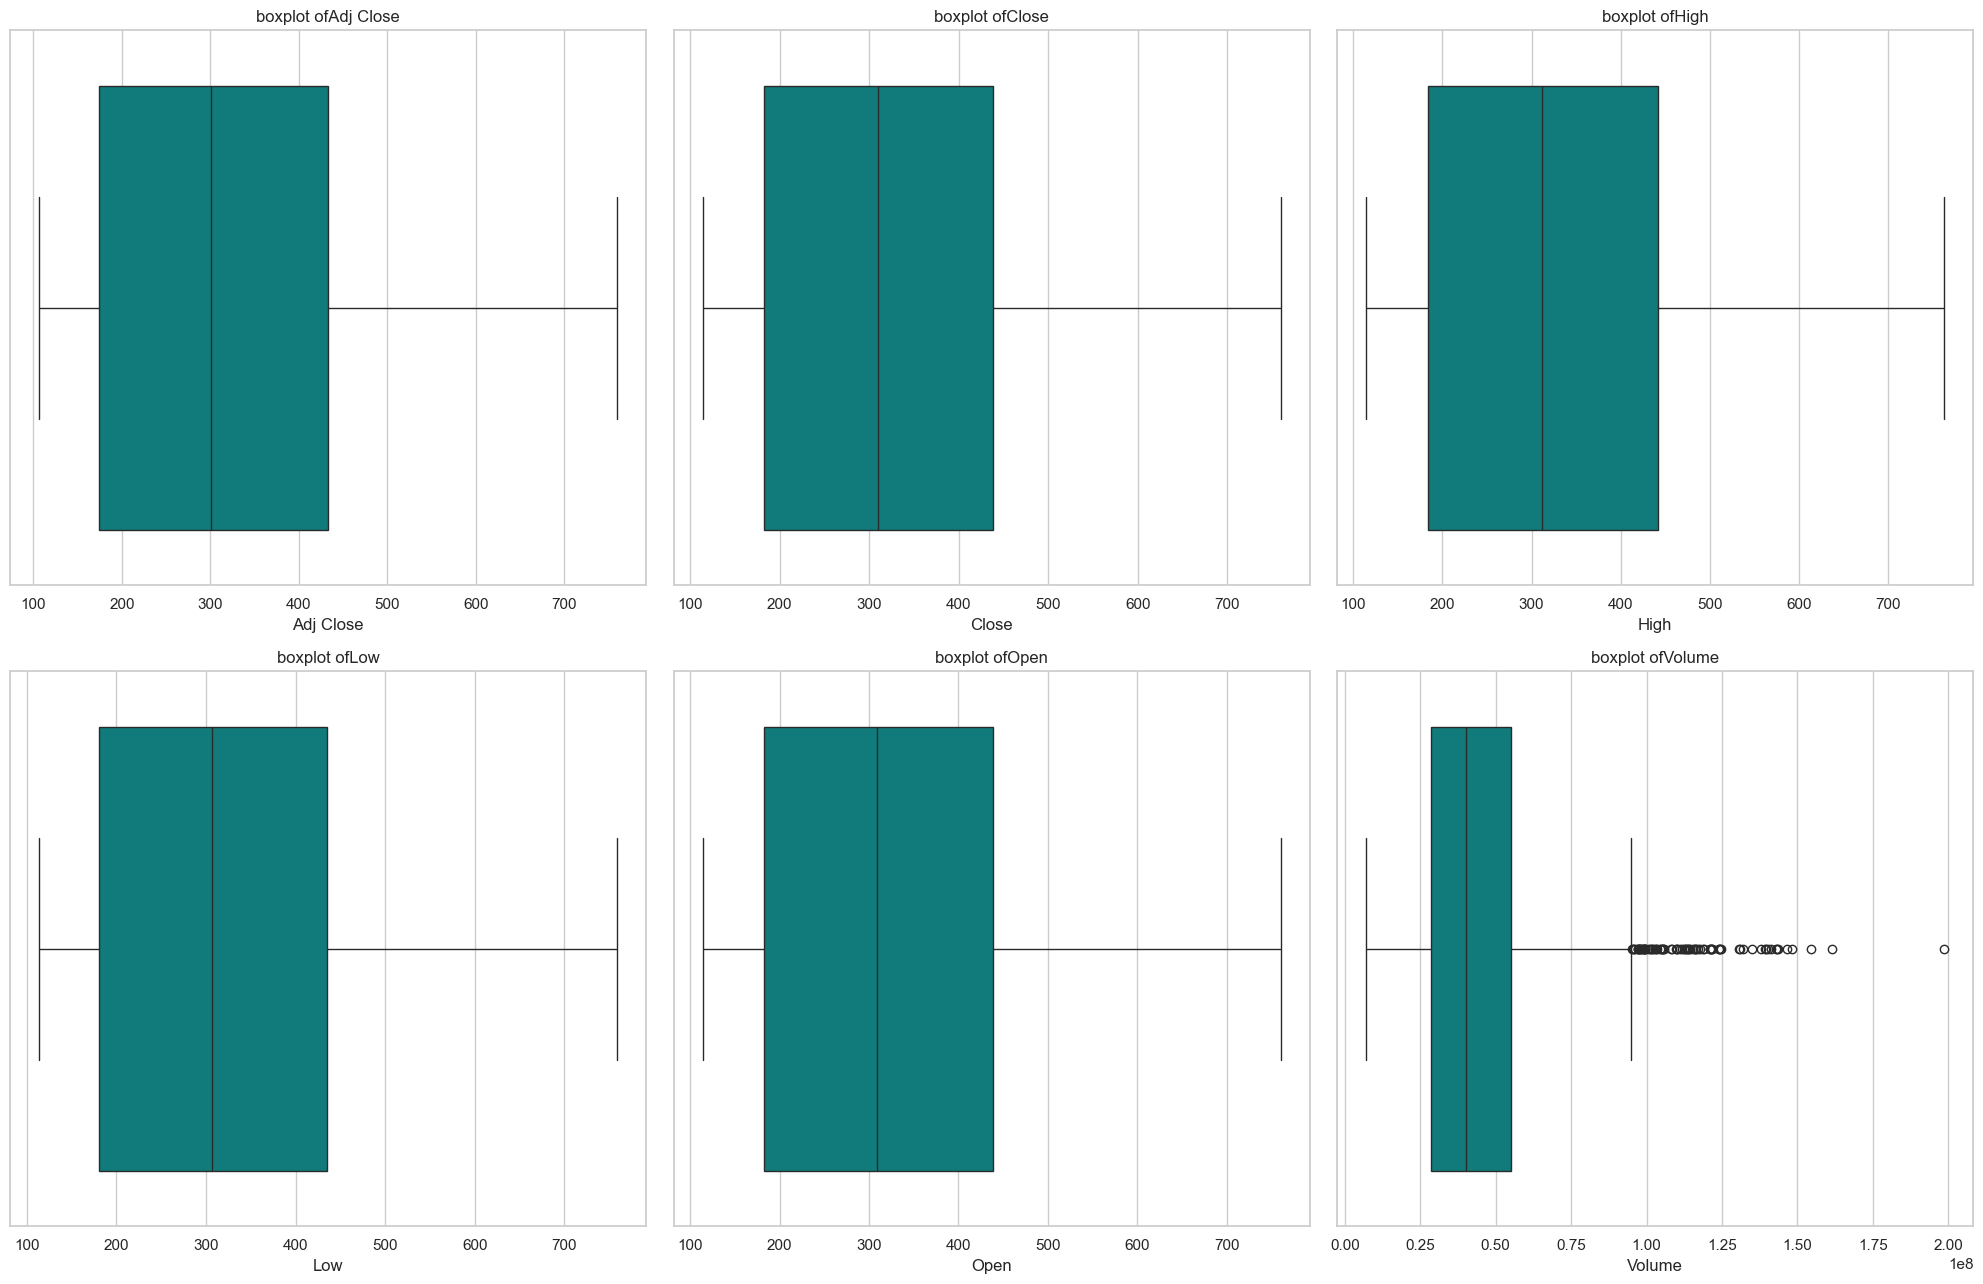

In [10]:
# Boxplots for each variable
Columns_num=['Adj Close', 'Close', 'High', 'Low', 'Open','Volume']
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(20,13))
axes = axes.flatten()

for i, col in enumerate(Columns_num):
    sns.boxplot(x=df_QQQ[col], ax=axes[i], color='darkcyan')
    axes[i].set_title(f'boxplot of{col}')

for j in range(len(Columns_num), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

Based on the Boxplot:

*Start Year*
-The varible Start Year  is not showing Outliers.

*matched_VEI*
-The varible Matched VEI has 0,5 and 6 as outliers, however the measures are a valid categories it means those are no mistakes and they are a value information for the model.

*gdp_per_capita* 
-The variable is showing multiple outliers in the upper tail (High-income countries).Combined with the  strong right-skewness observed in the histogram, it is necesary apply one strategy to combat positive skew, there is five key transformations five key transformations: Log, Square Root, Box-Cox, Yeo-Johnson, and Quantile Transformations. Each method aims to mitigate skewness (Chugani, 2024). After doing the analysis of each one the simplest way to minimizing the large- scale differences is Log transformation. This technique should be applyed in 4. Data preparation and preprocessing

*governance_avg*
-The varible governance_avg is showing as outliers the countries with strong governance those are relevant information for the model.

*Total Affected*
-The variable Total Affected is showing as outliers the eruptions whit massive impact (from 250.000 to 1,7000,000 affected people). However, as gdp_per capita jas  strongly right-skewes distribution  a log transformation will be applied in section 4.

for the last variables Outliers wont be removed because all values represent real volcanic information and events.


#### 2.2.4 Correlations

To understand how the variables are linked between them and find the statistical relation between two variables I'll apply the correlation   

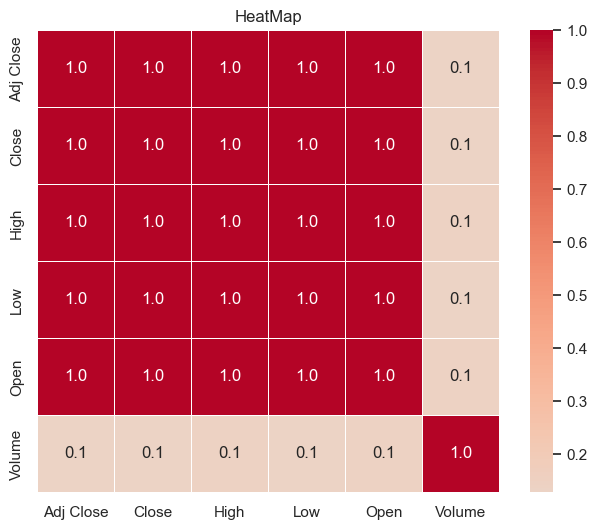

In [11]:
Columns_num=['Adj Close', 'Close', 'High', 'Low', 'Open','Volume']
corr = df_QQQ[Columns_num].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.1f',
           cmap='coolwarm', center=0, square=True,
           linewidths=0.5)
plt.title("HeatMap")
plt.show()

Most correlations between features are near zero, indicating no multicollinearity. The only notable correlation is between GDP per capita and Governance (r=0.6), a moderate positive relation. It means that countries with higher income tend to have stronger governance. According to common rules of  multicollinearity since 0.6 below this threshold, both features are reatined in the model(Dormann et al., 2012). 

#### 2.2.6 Relation between variables

In [12]:
#### price vs volum

In [13]:
df_QQQ['Volatility']= df_QQQ['High'] - df_QQQ['Low']

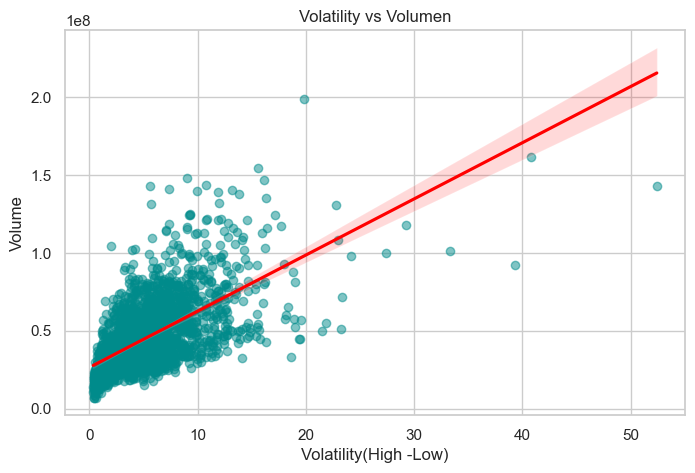

In [14]:
plt.figure(figsize=(8,5))
sns.regplot(x='Volatility', y='Volume', scatter_kws={'alpha':0.5}, color='darkcyan', line_kws={'color':'red'},
          data=df_QQQ)
plt.title("Volatility vs Volumen")
plt.xlabel("Volatility(High -Low)")
plt.ylabel("Volume")
plt.show()

In [15]:
#.describe to Get the statisitical measures of Data set, count, mean, standard desviation minimun  and maximun value and the quartiles all of this are the measures of descriptive statistical for each variable
df_QQQ.describe()

,Adj Close,Close,High,Low,Open,Volume,Volatility
count,2513.000000,2513.000000,2513.000000,2513.000000,2513.000000,2.513000e+03,2513.000000
mean,324.315839,331.412543,333.727055,328.734262,331.346450,4.443782e+07,4.992793
std,165.610147,163.633973,164.617143,162.464315,163.632783,2.198598e+07,3.894413
min,106.206009,113.650002,114.540001,113.449997,113.769997,7.079300e+06,0.369995
25%,174.408707,182.639999,183.809998,181.059998,182.399994,2.849590e+07,2.190002
50%,300.353302,309.250000,311.880005,306.399994,309.029999,4.011360e+07,4.279999
75%,432.523743,438.269989,441.600006,435.109985,438.230011,5.517260e+07,6.670044
max,759.659973,759.659973,762.859985,759.099976,760.520020,1.986858e+08,52.399994


## 3. Data Preparation

### 3.1 Cleaning dataset

#### 3.1.1 Handing dupplicated
To getting the total of duplicates in the data set I apply the .Duplicate() formula. In case that it will be different to 0, I will remove it because this could alter my data and analysis.

In [16]:
DUP = df_QQQ.duplicated().sum()
DUP

0

#### 3.1.2 Handle missing values

Handling missing values, is one of the most important things to verify because it can be affecting the analysis and models behaviour in consequence the models can learn wrong patterns making a default system behaviour. I'll use  the formule.isnill().sum() to know how many missing values have each category.


In [17]:
 df_QQQ.isnull().sum()

Date          0
Adj Close     0
Close         0
High          0
Low           0
Open          0
Volume        0
Volatility    0
dtype: int64

### 3.2 Feature Engineering

This is one of the most relevant steps before Modeling, as I have a series of prices and they are non-stationary time series becuse the mean, variance and correlation it is not constant because the median rise every year moreover the lowest price was $89, and the higuest price was  $756,  in conclution, the serie of proces is non stacionary time series and It has trend. It represent a problem because ARIMA demands seasonality.

In [18]:
df_QQQ.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2513 entries, 0 to 2512
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Date        2513 non-null   object 
 1   Adj Close   2513 non-null   float64
 2   Close       2513 non-null   float64
 3   High        2513 non-null   float64
 4   Low         2513 non-null   float64
 5   Open        2513 non-null   float64
 6   Volume      2513 non-null   int64  
 7   Volatility  2513 non-null   float64
dtypes: float64(6), int64(1), object(1)
memory usage: 157.2+ KB


#### 3.2.1 Log_Return

Log returns are a smart way to measure price changes (Muller, 2023), The mathemathical models works bette with the same scale, this variable allows the model compare the prices between the years or days it compare today's closing prices with yesterday's and allows clustering gropup per behaviour and trend not with years.

Formula: ln(P_t / P_{t-1})

In [19]:
#Convert date to date type
df_QQQ['Date'] = pd.to_datetime(df_QQQ['Date'])
#Sorting the rows from the oldest to the youngest
df_QQQ = df_QQQ.sort_values('Date').reset_index(drop=True)
#applying the formula of log_return
df_QQQ['Log Return'] = np.log(df_QQQ['Adj Close']/ df_QQQ['Adj Close'].shift(1))
#dropping the first raw because it generate nan
df_QQQ = df_QQQ.dropna(subset=['Log Return']).reset_index(drop=True)
print(df_QQQ.shape)
df_QQQ[['Date', 'Adj Close', 'Log Return']].head()

(2512, 9)


,Date,Adj Close,Log Return
0,2016-10-11,109.822517,-0.014362
1,2016-10-12,109.729088,-0.000851
2,2016-10-13,109.336594,-0.003583
3,2016-10-14,109.467422,0.001196
4,2016-10-17,109.168396,-0.002735


#### 3.2.2 Range_pct

The Range_ pct variable it is on of the most important variables in trading it allows to measure how much the ETF's price moved during the day in percentage(%), because naturally two days with the same closing price can be very different.To do the clustering  this variable give the algorthmin a features where it can distinguish  between days that look the same at first glance but they are very differnt of their behavior.

Formula: Range pct= (High - low)/  Close*100

In [20]:
df_QQQ['Range pct'] = (df_QQQ['High']- df_QQQ['Low'])/ df_QQQ['Close']*100
print(df_QQQ.shape)
df_QQQ[['High', 'Low', 'Close', 'Range pct']].head()

(2512, 10)


,High,Low,Close,Range pct
0,119.139999,117.000000,117.519997,1.820966
1,117.820000,117.059998,117.419998,0.647251
2,117.320000,115.940002,117.000000,1.179485
3,118.050003,117.070000,117.139999,0.836609
4,117.300003,116.669998,116.820000,0.539295


#### 3.2.3 Log_Volume

Log volume allows the algoritmic normalice the volume to works easier, because it reduce the bias and the assimetry. Usually the Transaction volume in trading is often highly skewed and spans extreme ranges (from thousands to billions). When a logarithm is applied, the distribution becomes more symmetrical and closer to a normal curve (Goyenko et al., 2024) it means that it reduces the outliers and improve the stability of clustering models and series times.

formula: Log_Volume = log10(volume)

In [21]:
df_QQQ['Log Volume'] = np.log10(df_QQQ['Volume'])
print(df_QQQ.shape)
df_QQQ[['Date', 'Volume','Log Volume']].head()

(2512, 11)


,Date,Volume,Log Volume
0,2016-10-11,27774400,7.443645
1,2016-10-12,14267800,7.154357
2,2016-10-13,22821000,7.358335
3,2016-10-14,21313300,7.328651
4,2016-10-17,14182700,7.151759


#### 3.2.4 Volatility_20

The volatility allows the algorithmin measure how much returns fluctuate over time and higuer values indicate a more unstable market(Hayes,2025).It is calculated with the stard deviation  of the returns over 1 month window, exactly 20 days because the stock market has moviments weekly.

formula>

In [22]:
df_QQQ['Volatility_20'] = df_QQQ['Log Return'].rolling(20).std()
df_QQQ[['Date', 'Log Return','Volatility_20']].head(30)

,Date,Log Return,Volatility_20
0,2016-10-11,-0.014362,NaN
1,2016-10-12,-0.000851,NaN
2,2016-10-13,-0.003583,NaN
3,2016-10-14,0.001196,NaN
4,2016-10-17,-0.002735,NaN
5,2016-10-18,0.008863,NaN
6,2016-10-19,-0.000085,NaN
7,2016-10-20,-0.001189,NaN
8,2016-10-21,0.003731,NaN
9,2016-10-24,0.011947,NaN


cleaning the Nan 

#### 3.2.5 Volume_Ratio

In [23]:
df_QQQ['Volume_MA20'] = df_QQQ['Volume'].rolling(20).mean()
df_QQQ['Volume_Ratio'] = df_QQQ['Volume']/ df_QQQ['Volume_MA20']
df_QQQ[['Date', 'Volume','Volume_MA20','Volume_Ratio']].head(30)

,Date,Volume,Volume_MA20,Volume_Ratio
0,2016-10-11,27774400,NaN,NaN
1,2016-10-12,14267800,NaN,NaN
2,2016-10-13,22821000,NaN,NaN
3,2016-10-14,21313300,NaN,NaN
4,2016-10-17,14182700,NaN,NaN
5,2016-10-18,19276700,NaN,NaN
6,2016-10-19,13702900,NaN,NaN
7,2016-10-20,18132200,NaN,NaN
8,2016-10-21,15707800,NaN,NaN
9,2016-10-24,19143000,NaN,NaN


In [24]:
df_QQQ.head(30)

,Date,Adj Close,Close,High,Low,Open,Volume,Volatility,Log Return,Range pct,Log Volume,Volatility_20,Volume_MA20,Volume_Ratio
0,2016-10-11,109.822517,117.519997,119.139999,117.000000,119.120003,27774400,2.139999,-0.014362,1.820966,7.443645,NaN,NaN,NaN
1,2016-10-12,109.729088,117.419998,117.820000,117.059998,117.629997,14267800,0.760002,-0.000851,0.647251,7.154357,NaN,NaN,NaN
2,2016-10-13,109.336594,117.000000,117.320000,115.940002,116.620003,22821000,1.379997,-0.003583,1.179485,7.358335,NaN,NaN,NaN
3,2016-10-14,109.467422,117.139999,118.050003,117.070000,117.580002,21313300,0.980003,0.001196,0.836609,7.328651,NaN,NaN,NaN
4,2016-10-17,109.168396,116.820000,117.300003,116.669998,117.040001,14182700,0.630005,-0.002735,0.539295,7.151759,NaN,NaN,NaN
5,2016-10-18,110.140259,117.860001,118.410004,117.800003,118.209999,19276700,0.610001,0.008863,0.517564,7.285033,NaN,NaN,NaN
6,2016-10-19,110.130913,117.849998,118.019997,117.639999,117.769997,13702900,0.379997,-0.000085,0.322441,7.136812,NaN,NaN,NaN
7,2016-10-20,110.000069,117.709999,117.970001,117.029999,117.730003,18132200,0.940002,-0.001189,0.798575,7.258451,NaN,NaN,NaN
8,2016-10-21,110.411278,118.150002,118.220001,117.410004,117.800003,15707800,0.809998,0.003731,0.685567,7.196115,NaN,NaN,NaN
9,2016-10-24,111.738251,119.570000,119.650002,118.889999,118.910004,19143000,0.760002,0.011947,0.635613,7.282010,NaN,NaN,NaN


In [25]:
 df_QQQ.isnull().sum()

Date              0
Adj Close         0
Close             0
High              0
Low               0
Open              0
Volume            0
Volatility        0
Log Return        0
Range pct         0
Log Volume        0
Volatility_20    19
Volume_MA20      19
Volume_Ratio     19
dtype: int64

In [26]:
df_QQQ=df_QQQ.dropna().reset_index(drop=True)
df_QQQ.isnull().sum()

Date             0
Adj Close        0
Close            0
High             0
Low              0
Open             0
Volume           0
Volatility       0
Log Return       0
Range pct        0
Log Volume       0
Volatility_20    0
Volume_MA20      0
Volume_Ratio     0
dtype: int64

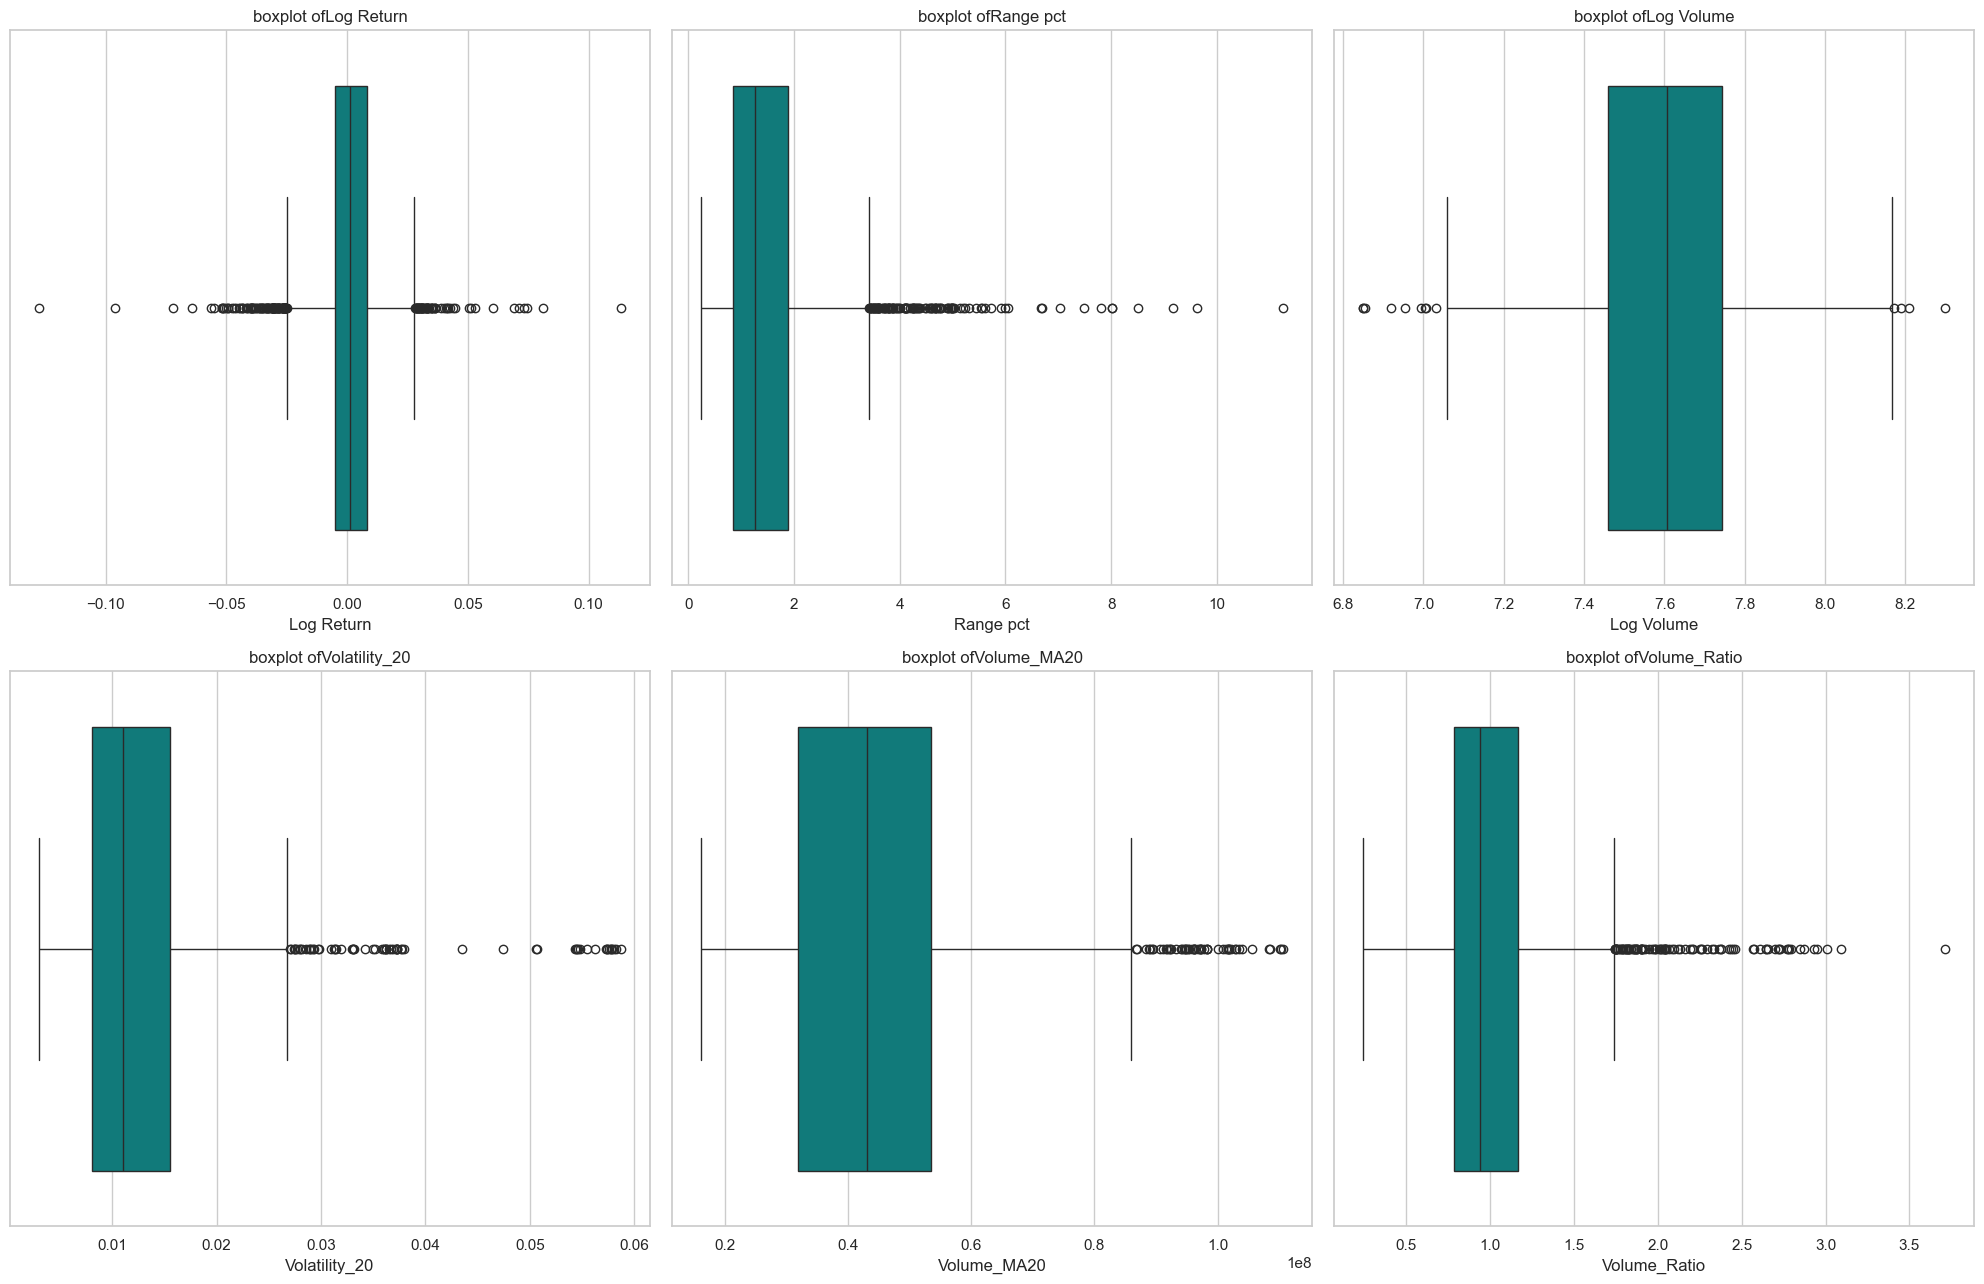

In [27]:
# Boxplots for each variable
Columns_num=['Log Return', 'Range pct', 'Log Volume',
           'Volatility_20','Volume_MA20','Volume_Ratio']
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(20,13))
axes = axes.flatten()

for i, col in enumerate(Columns_num):
    sns.boxplot(x=df_QQQ[col], ax=axes[i], color='darkcyan')
    axes[i].set_title(f'boxplot of{col}')

for j in range(len(Columns_num), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

### 3.4 Scaling
It is  necessary to apply the standardization of numerical variables because each has its own scale, to choose what technique is the best option to scale the data set : 1. Min-max Normalization: This type is used when we know the lower and upper limits and these are fixed. In this case, it is not the most appropriate technique because after log-transformation the influence of outliers is reduced. 2. Standardization: this technique works best when data is approximately normal, after the log-transformation is approximaterly normal.

In [28]:
from sklearn.preprocessing import RobustScaler

In [29]:

#features to scalling
features =['Log Return', 'Range pct', 'Log Volume',
           'Volatility_20','Volume_MA20','Volume_Ratio']
#Applying scaler
scaler = RobustScaler()
df_QQQ[['Log Return_scaled',
          'Range pct_scaled',
          'Log Volume_scaled',
         'Volatility_20_scaled',
         'Volume_MA20_scaled',
         'Volume_Ratio_scaled']] = scaler.fit_transform(df_QQQ[features])
#verifying the result
print()
print("scaled features:")
print(df_QQQ[['Log Return_scaled',
          'Range pct_scaled',
          'Log Volume_scaled',
         'Volatility_20_scaled',
         'Volume_MA20_scaled',
         'Volume_Ratio_scaled']].describe().round(2))


scaled features:
       Log Return_scaled  Range pct_scaled  Log Volume_scaled  \
count            2493.00           2493.00            2493.00   
mean               -0.04              0.25              -0.01   
std                 1.08              0.98               0.72   
min                -9.75             -0.99              -2.66   
25%                -0.49             -0.40              -0.52   
50%                 0.00              0.00               0.00   
75%                 0.51              0.60               0.48   
max                 8.47              9.71               2.44   

       Volatility_20_scaled  Volume_MA20_scaled  Volume_Ratio_scaled  
count               2493.00             2493.00              2493.00  
mean                   0.21                0.07                 0.19  
std                    0.93                0.76                 0.94  
min                   -1.07               -1.24                -1.82  
25%                   -0.39              

In [30]:
df_scaled=df_QQQ[['Log Return_scaled','Range pct_scaled','Log Volume_scaled',
                  'Volatility_20_scaled','Volume_Ratio_scaled']]
df_scaled.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2493 entries, 0 to 2492
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Log Return_scaled     2493 non-null   float64
 1   Range pct_scaled      2493 non-null   float64
 2   Log Volume_scaled     2493 non-null   float64
 3   Volatility_20_scaled  2493 non-null   float64
 4   Volume_Ratio_scaled   2493 non-null   float64
dtypes: float64(5)
memory usage: 97.5 KB


### 3.4.1 EDA Scaled variables

fter understanding the dtype of each feature it is important to examine the characteristic of the data, as distribution, unusual values and potential issues. For this purpose, I will analyse the variables numericals doing a univariable analysis and bivariate analysis.

##### Univariable Analysis - Histogram Numerical Variables scaled.

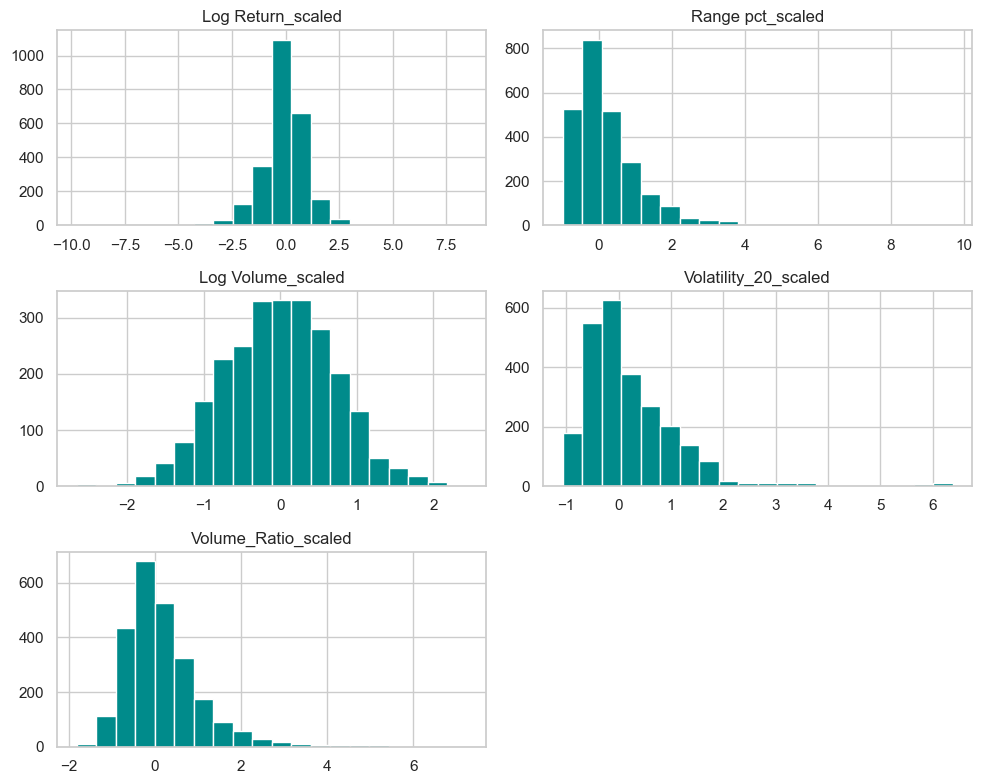

In [31]:
df_scaled.hist(figsize=(10,8), bins=20, color="darkcyan")
plt.tight_layout()
plt.show()

#### Boxplots scaled variables

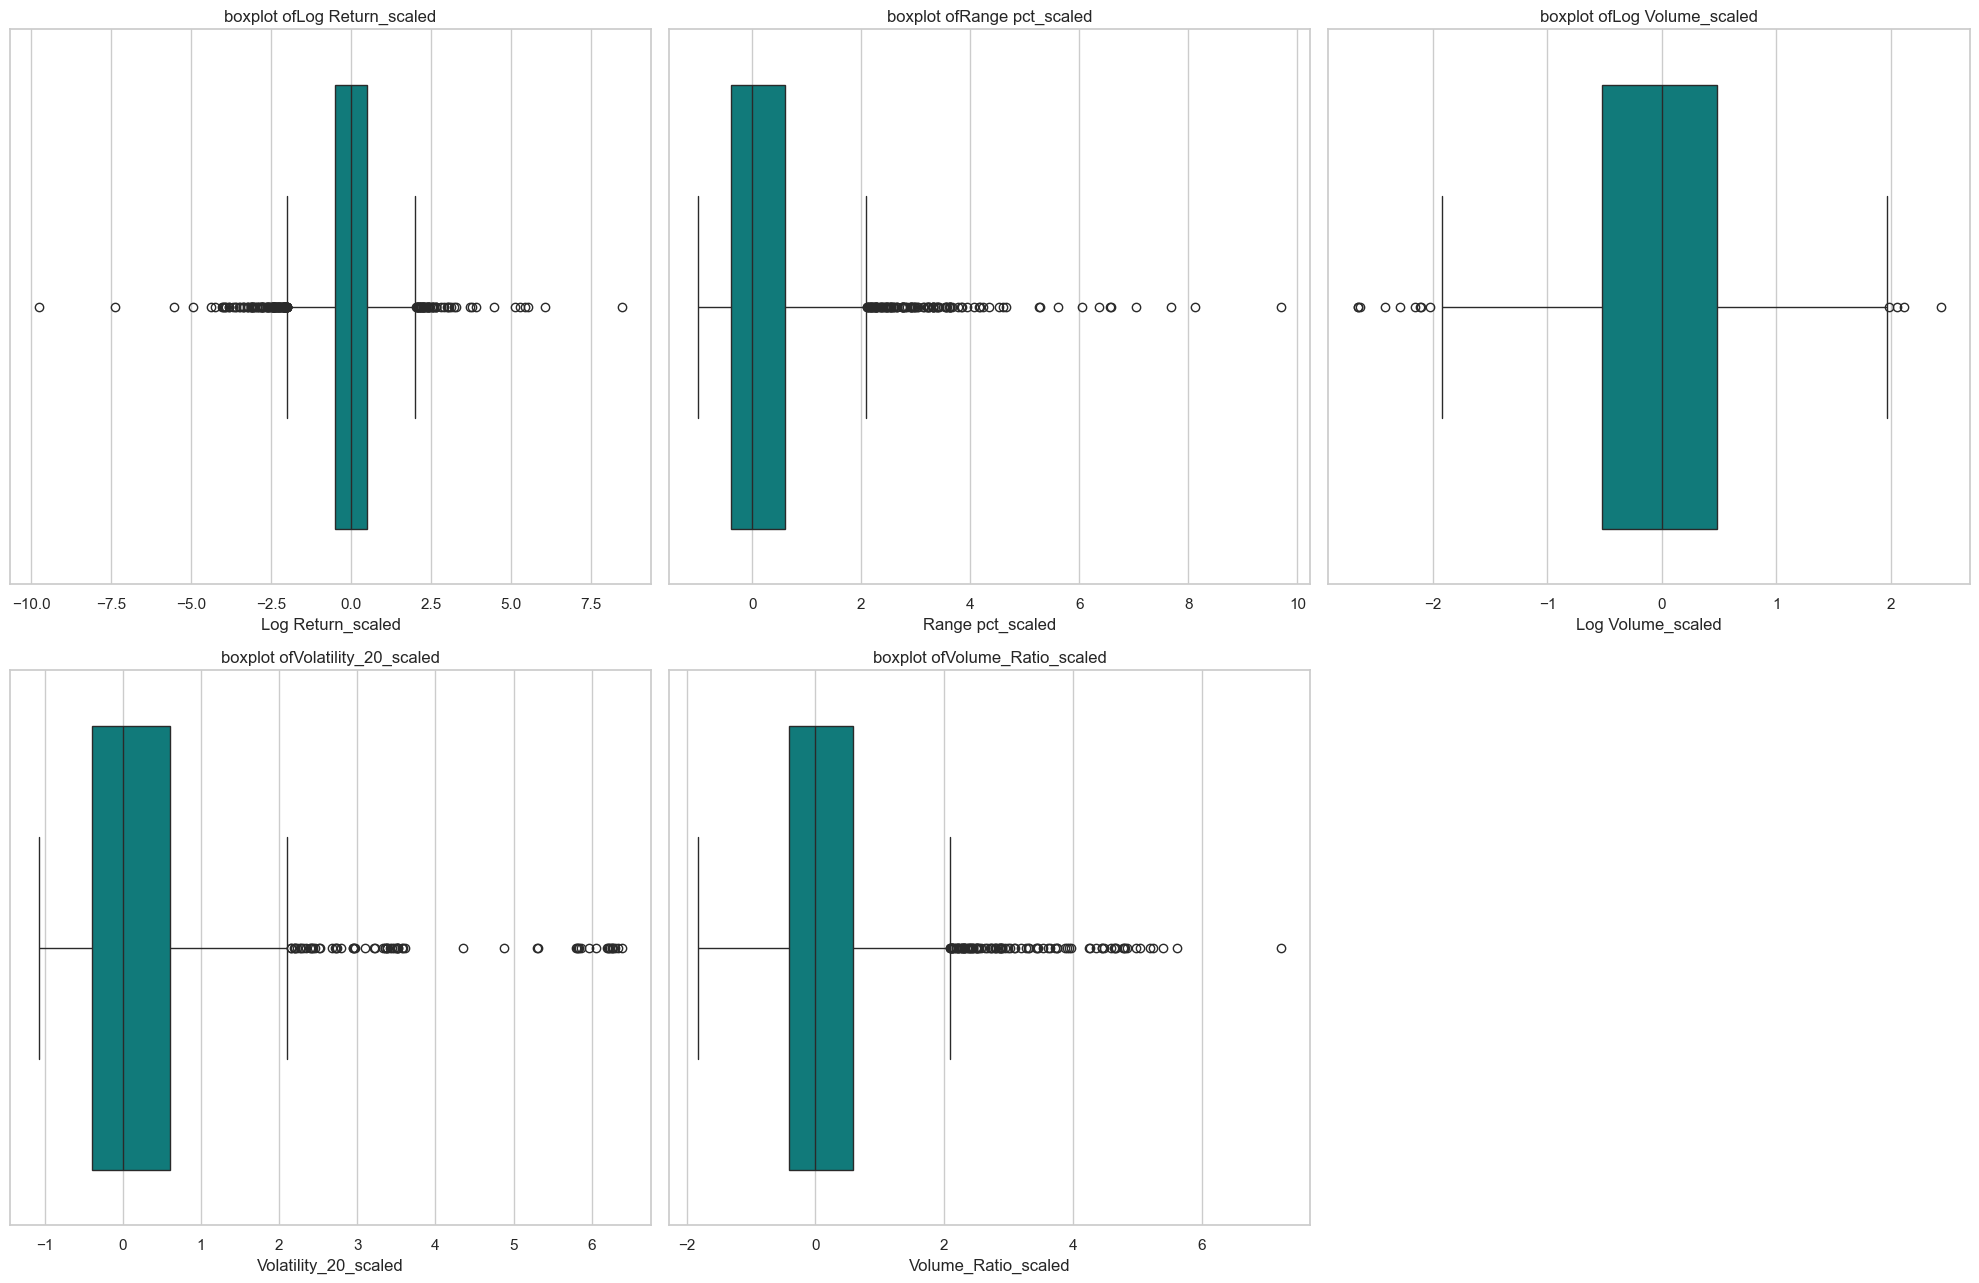

In [32]:
# Boxplots for each variable
Columns_num_scaled=['Log Return_scaled','Range pct_scaled','Log Volume_scaled','Volatility_20_scaled','Volume_Ratio_scaled']
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(20,13))
axes = axes.flatten()

for i, col in enumerate(Columns_num_scaled):
    sns.boxplot(x=df_scaled[col], ax=axes[i], color='darkcyan')
    axes[i].set_title(f'boxplot of{col}')

for j in range(len(Columns_num_scaled), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

#### Correlations

To understand how the variables are linked between them and find the statistical relation between two variables I'll apply the correlation   

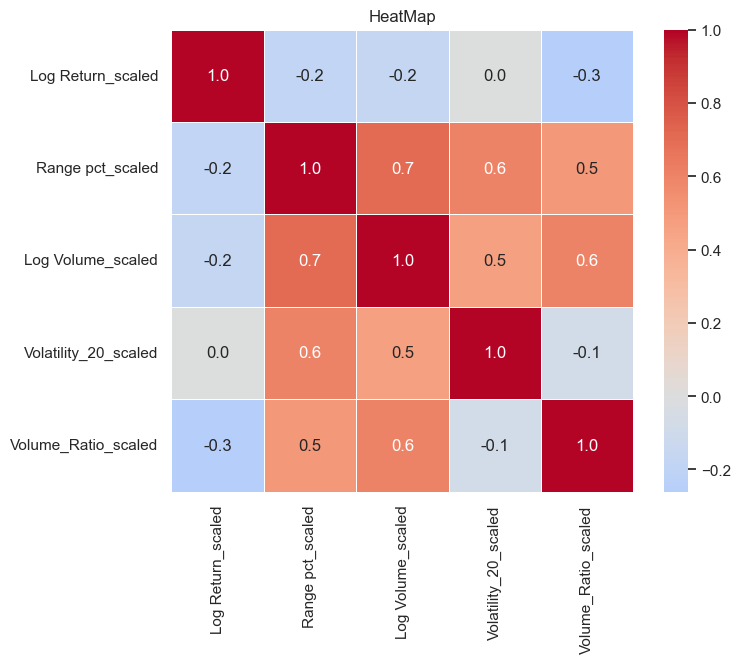

In [33]:
corr = df_scaled.corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.1f',
           cmap='coolwarm', center=0, square=True,
           linewidths=0.5)
plt.title("HeatMap")
plt.show()

### 3.5 PCA

The clustering is an unsepervised learning problem where no predifined labels exist.

In [34]:
#Import library
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [35]:
#Applying pca variance 0,98
X = df_scaled
pca_1 = PCA(n_components=0.98)
X_pca = pca_1.fit_transform(X)
print("Components sel", pca_1.n_components_)
print("Cumulative Variance:", sum(pca_1.explained_variance_ratio_) )

Components sel 5
Cumulative Variance: 0.9999999999999997


In [36]:
pca_2 = PCA(n_components=2)
X_pca2 = pca_2.fit_transform(X)
print(pca_2.explained_variance_ratio_.sum())

0.7406144808714281


I ll continue with the X, the first 2  dimentions  present 3/4 partes of the information. AS THE PCA DONT consevethe 5 components  ill continue with x with no pca 

## 4. Modeling Clustering 

### 4.1 Selection of the algorithm

The object of this projects is segment trading days according to their behavior, It  has not labels  that why the project shpuld be a unsupervised learning. To chose the correct model it is important analisar el EDA: 

1. After getting the Boxplot graphics we have strong Outliers (Log Return, Range pct, Volatility_20 and volume ratio. those are real values that is why I didnt delte it.
2. the variables Range pct, volatility_20 and volume Ratio have symetry to the right.
3. The PCA Contains the 5 components,  it means that there is no reduccion of variables. 

The algorithms that was selected to do the clustering are: 

K-means: Asings each days a cluster and their centroides itll be reading directly. 
Fuzzy c   

### 4.2 K-Means 

K-means clustering is a type of unsupervised learning, which is used when you have unlabeled data (i.e., data without defined categories or groups). The goal of this algorithm is to find groups in the data, with the number of groups represented by the variable K. The algorithm works iteratively to assign each data point to one of K groups based on the features that are provided (Trevino, 2025). To do the Kmeans the parameter to use is:
n_clusters =3, I'll use kmeans 3 because we have  dias alcistas (subidas), dias bajistas (caidas) and  dias tranquilos. 
n_init= run algorithm 10 times with different centroid seeds

In [37]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [38]:
# Load 4 columns of the Iris data values
# x = dataset.iloc[:, [1, 2, 3, 4]].values
x = df_scaled[['Log Return_scaled','Range pct_scaled', 'Log Volume_scaled',
               'Volatility_20_scaled','Volume_Ratio_scaled']].values
print(x)

[[ 1.67270559 -0.2491241  -0.63590804 -0.34574546  0.70115378]
 [ 0.38957651  0.16795343 -1.01292256 -0.40385037  0.05183512]
 [ 0.24514669  0.6243481   0.84845578 -0.39465341  5.04151858]
 ...
 [ 0.24246195 -0.74560034 -0.64037451 -0.17398672 -0.37925738]
 [-0.29508342 -0.38637516 -0.70187133 -0.17525761 -0.45709297]
 [-1.1224707   0.58747112  0.31976228 -0.14532332  1.33565471]]


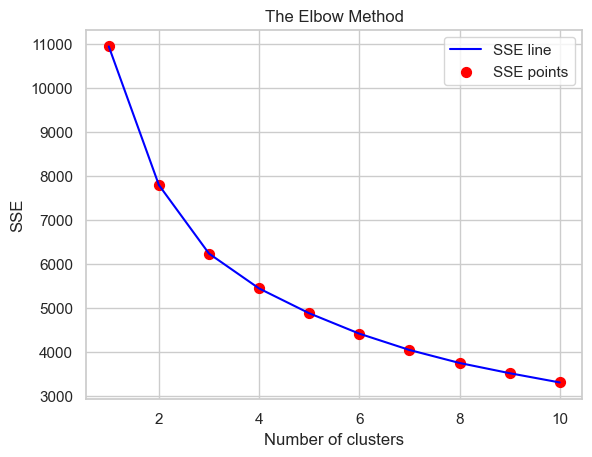

In [39]:
# Finding the optimum number of clusters for k-means classification
sse = []   # Declare an array for the storage of values for Sum of Squares (SSE) Errors

# Set the loop from the minimum and maximum values
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, max_iter = 300, n_init = 10, random_state = 38)  # Initialise an object kmeans by calling 
                                                                                     # an object KMeans()
    kmeans.fit(x)                                                                    # Training the model by calling fit() method
    sse.append(kmeans.inertia_)                                                      # Store kmeans.inertia_ in the array sse

# Plotting the results onto a line graph with points in a different color
plt.plot(range(1, 11), sse, linestyle = '-', color = 'blue', label = 'SSE line')
plt.scatter(range(1, 11), sse, color = 'red', marker = 'o', s = 50, label = 'SSE points')

plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('SSE')  # sum of squares errors
plt.legend()
plt.show()

In [40]:
# Applying KMeans to the dataset/ Creating the kmeans classifier
# 3 clusters
kmeans = KMeans(n_clusters = 3, max_iter = 300, n_init = 10, random_state = 38)

# n_initial, default = 10, Number of time the k-means algorithm will be run with different centroid seeds. 
# The final results will be the best output of n_init consecutive runs in terms of inertia.
y_kmeans = kmeans.fit_predict(x)

In [41]:
# Loop through cluster numbers from 2 to 9
for n_clusters in range(2, 10):
    kmeans = KMeans(n_clusters = n_clusters, random_state = 42)
    labels = kmeans.fit_predict(x)                                # Fit and predict cluster labels
    score = silhouette_score(x, labels)
    print(f"Silhouette Score (n = {n_clusters}): {score:.4f}")
sil_score = silhouette_score(x, y_kmeans)
# Display the silhouette score values
print(f'Silhouette Score(n = 3): {silhouette_score(x, y_kmeans)}')

Silhouette Score (n = 2): 0.3977
Silhouette Score (n = 3): 0.3611
Silhouette Score (n = 4): 0.2674
Silhouette Score (n = 5): 0.2766
Silhouette Score (n = 6): 0.2139
Silhouette Score (n = 7): 0.2328
Silhouette Score (n = 8): 0.2187
Silhouette Score (n = 9): 0.2120
Silhouette Score(n = 3): 0.3611408810616438


In [42]:
# Display the David Bouldin score values
db_score = davies_bouldin_score(x, y_kmeans)
print(f'Davies_bouldin_score(n = 3): {silhouette_score(x, y_kmeans)}')

Davies_bouldin_score(n = 3): 0.3611408810616438


In [43]:
# adjust PCA to reduce from 5D to 2D

In [44]:
centroids_pca = pca_2.transform(kmeans.cluster_centers_)

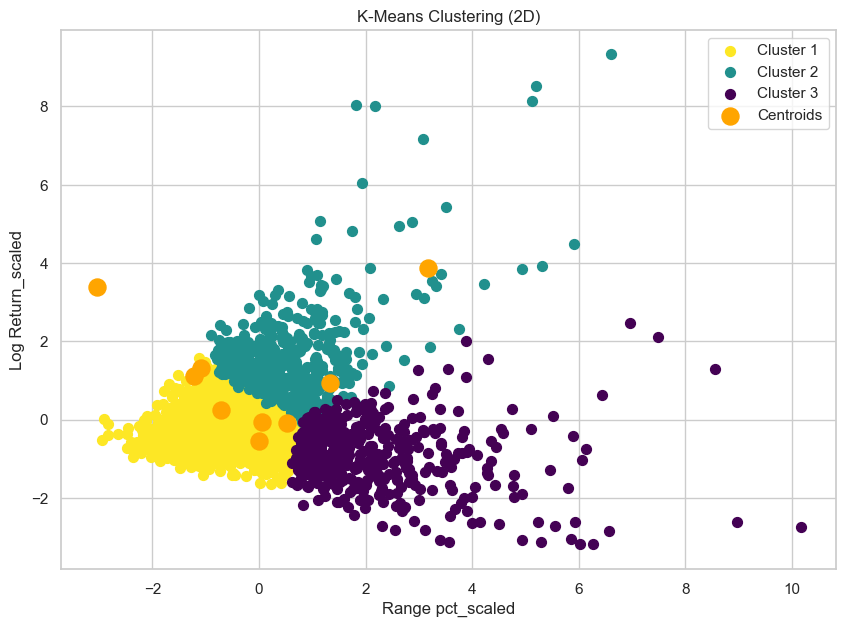

In [45]:
plt.figure(figsize=(10,7))

# Visualising the clusters using scatter() method
plt.scatter(X_pca2[y_kmeans == 0, 0], X_pca2[y_kmeans == 0, 1], s = 50, c = '#FDE725', label = 'Cluster 1')
plt.scatter(X_pca2[y_kmeans == 1, 0], X_pca2[y_kmeans == 1, 1], s = 50, c = '#21908D', label = 'Cluster 2')
plt.scatter(X_pca2[y_kmeans == 2, 0], X_pca2[y_kmeans == 2, 1], s = 50, c = '#440154', label = 'Cluster 3')

# Plotting the centroids of the clusters
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:,1], s = 150, c = 'orange', 
            label = 'Centroids')
plt.xlabel('Range pct_scaled')
plt.ylabel('Log Return_scaled')
plt.title('K-Means Clustering (2D)')
plt.legend(loc='best')
plt.show()

# A legend is an area describing the elements of the graph. In the matplotlib library, there's a function called legend() 
# which is used to Place a legend on the axes.
# plt.legend( loc ="best") 

### 4.3 Fuzzy C

#### KMeans Clustering

In [53]:
kmeans = KMeans(n_clusters = 3, random_state = 42)
kmeans_labels = kmeans.fit_predict(X)

#### Fuzzy CMeans Clustering

In [47]:
from sklearn.cluster import KMeans
import numpy as np
import skfuzzy as fuzz

# Select two features for clustering
x = df_scaled[['Log Return_scaled','Range pct_scaled', 'Log Volume_scaled',
               'Volatility_20_scaled','Volume_Ratio_scaled']].values

In [48]:
# Transpose the data matrix so that each row represents a feature and each column represents a data point. 
# The skfuzzy cmeans() function expects input in this format.

x_fcm = x.T

# Declare the number of clusters
n_clusters = 3

# Initilise the model object
cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(x_fcm, c = n_clusters, m = 2, error = 0.005,
                                                 maxiter = 1000, init = None, seed = 42)

# pick highest membership
fcm_labels = np.argmax(u, axis=0)
sil_fcm = silhoutte_score(x, fmc_labels)

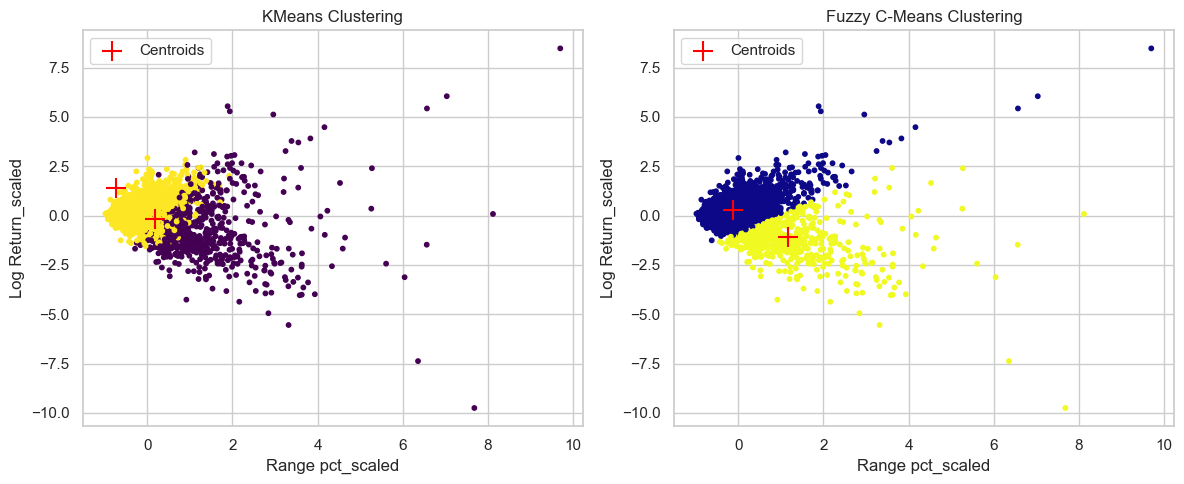

In [49]:
import matplotlib.pyplot as plt

# Plot KMeans results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(x[:, 0], x[:, 1], c=kmeans_labels, cmap="viridis", s=10)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            c="red", marker="+", s=200, label="Centroids")
plt.title("KMeans Clustering")
plt.xlabel("Range pct_scaled")
plt.ylabel("Log Return_scaled")
plt.legend()

# Plot FCM results
plt.subplot(1, 2, 2)
plt.scatter(x[:, 0], x[:, 1], c=fcm_labels, cmap="plasma", s=10)
plt.scatter(cntr[:, 0], cntr[:, 1], c="red", marker="+", s=200, label="Centroids")
plt.title("Fuzzy C-Means Clustering")
plt.xlabel("Range pct_scaled")
plt.ylabel("Log Return_scaled")
plt.legend()

plt.tight_layout()
plt.show()

#### Plot overlapped points on both clusters

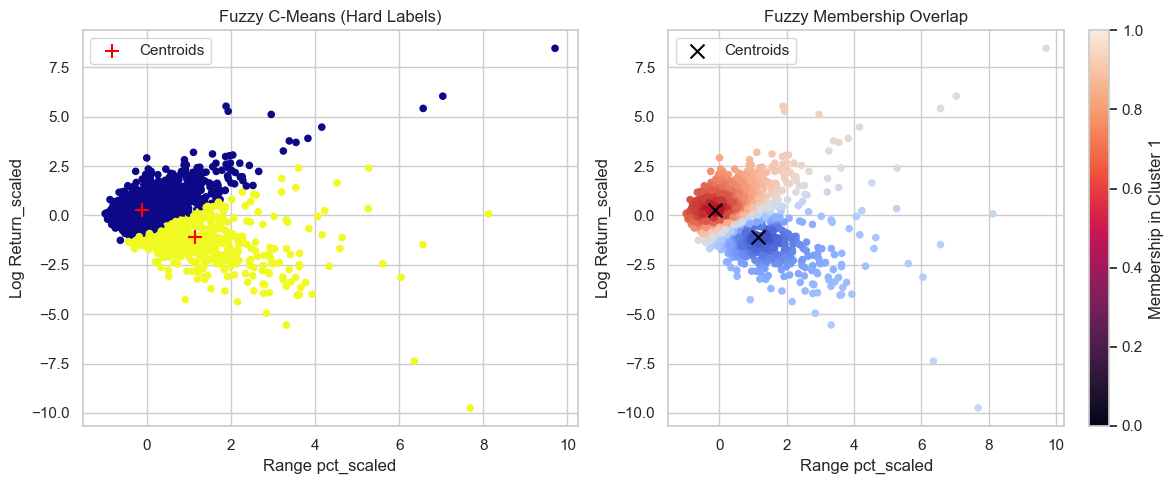

In [50]:
plt.figure(figsize=(12, 5))

# Subplot 1: Hard assignment (like KMeans)
plt.subplot(1, 2, 1)
fcm_labels = np.argmax(u, axis = 0)
plt.scatter(x[:, 0], x[:, 1], c = fcm_labels, cmap = "plasma", s = 20)
plt.scatter(cntr[:, 0], cntr[:, 1], c = "red", marker = "+", s = 100, label = "Centroids")
plt.title("Fuzzy C-Means (Hard Labels)")
plt.xlabel("Range pct_scaled")
plt.ylabel("Log Return_scaled")
plt.legend()

# Subplot 2: Membership strength (shows overlap)
plt.subplot(1, 2, 2)
# Use membership in cluster 1 as color intensity
plt.scatter(x[:, 0], x[:, 1], c = u[0], cmap = "coolwarm", s = 20)
plt.scatter(cntr[:, 0], cntr[:, 1], c = "black", marker = "x", s = 100, label = "Centroids")
plt.title("Fuzzy Membership Overlap")
plt.xlabel("Range pct_scaled")
plt.ylabel("Log Return_scaled")
cbar = plt.colorbar()
cbar.set_label("Membership in Cluster 1")
plt.legend()

plt.tight_layout()
plt.show()

In [51]:
import numpy as np

# Threshold on max membership
threshold = 0.6
max_memberships = np.max(u, axis=0)
overlap_mask = max_memberships <= threshold

# Identify overlapped points by either method
overlap_points = x[overlap_mask]

print(f"Overlap (max membership ≤ {threshold}): {len(overlap_points)} points")

# Example: print a few overlapped points with their memberships
for i, (point, mem) in enumerate(zip(x[overlap_mask], u.T[overlap_mask])):
    if i < 10:
        print(f"Point {point} -> memberships {mem}")


Overlap (max membership ≤ 0.6): 205 points
Point [ 0.38030261 -0.43208862] -> memberships [0.58057489 0.41942511]
Point [-0.04893286 -0.90336473] -> memberships [0.51880282 0.48119718]
Point [ 0.48631132 -0.31909204] -> memberships [0.59151709 0.40848291]
Point [ 0.38969585 -0.59502433] -> memberships [0.45097106 0.54902894]
Point [ 0.11037146 -0.74824012] -> memberships [0.52614028 0.47385972]
Point [3.21198266 1.87490749] -> memberships [0.48656998 0.51343002]
Point [3.20171716 1.19198716] -> memberships [0.4403425 0.5596575]
Point [1.71966668 1.30000706] -> memberships [0.57390186 0.42609814]
Point [ 0.54288651 -0.31801373] -> memberships [0.55092535 0.44907465]
Point [ 0.34314568 -0.58952848] -> memberships [0.4876555 0.5123445]


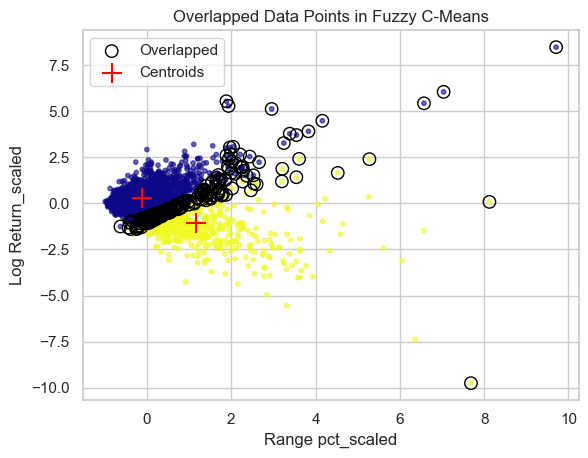

In [52]:
plt.scatter(x[:, 0], x[:, 1], c=np.argmax(u, axis=0), cmap = "plasma", s = 10, alpha = 0.6)
plt.scatter(overlap_points[:, 0], overlap_points[:, 1],
            edgecolors="black", facecolors="none", s=80, label="Overlapped")
plt.scatter(cntr[:, 0], cntr[:, 1], c="red", marker="+", s=200, label="Centroids")
plt.title("Overlapped Data Points in Fuzzy C-Means")
plt.xlabel("Range pct_scaled")
plt.ylabel("Log Return_scaled")
plt.legend()
plt.show()

### 4.4 Silhouette and Davies bouldin

#### 4.4.1 Silhouette and Davies bouldin Kmeans

### 4.5 comparation and interpretation of clusters

## 5. TIME SERIES-EDA

### 5.1 time series visualization (Close)

### 5.2 trend, seasonality and anomalies 

### 5.3 Decomposition

### 5.4 Stationarity test (ADF, KPSS).

### 5.5 ACF and PACF

### 5.6 Conclusions for selecting p,d, q.

## 6 ARIMA/SARIMA

### 6.1 Parameter determination

### 6.2 Model fitting

### 6.3 Forecasting evaluation (MAE,RMSE,MAPE).

### 6.4 Strengs and  limitations.

### 6.5 Conclusions for selecting p,d, q.

## 7. Evaluation

### 7.1 Integration of clustering results and temporal series.

### 7.2 Answer first objetives.

## 8. Conclutions

## 9. References


- @YahooFinance. (2019). NASDAQ Composite (^IXIC) Stock Price, Quote, History & News. [online] Available at: https://finance.yahoo.com/quote/%5EIXIC/ [Accessed 29 Sept. 2026].
- Ali, M. (2024). Agrupación en el aprendizaje automático: 5 Algoritmos de Agrupación Esenciales. [online] Datacamp.com. Available at: https://www.datacamp.com/es/blog/clustering-in-machine-learning-5-essential-clustering-algorithms [Accessed 3 Oct. 2026].
- Hayes, A. (2025). Volatility Definition. [online] Investopedia. Available at: https://www.investopedia.com/terms/v/volatility.asp [Accessed 6 Oct. 2026].
- Quantt (2026). ARIMA Model: Time Series Forecasting Explained 2026. [online] Quantt. Available at: https://www.quantt.co.uk/resources/arima-model-explained [Accessed 6 Oct. 2026].
[1] Rpubs.com. (2025). RPubs - Log Returns in Stock Market. [online] Available at: https://rpubs.com/sidewaysTimeTravel/1346935 [Accessed 6 Oct. 2026].
Ramuada, V.C. (2018). Forecasting Stock Returns: A Comparison of Five Models. [Academic thesis] Stellenbosch University. Available at:
- https://scholar.sun.ac.za/server/api/core/bitstreams/70ed3146-a1b2-475b-9519-232578edf560/content [Accessed 6 Oct. 2026].
Muller, D.S. (2023). Return Calculation. [online] EventStudy. Available at: https://eventstudy.de/docs/return-calculation [Accessed 6 Oct. 2026].
-https://www.utas.edu.au/__data/assets/pdf_file/0018/205182/03-2005_NJS-Error-Correction-Relationships-Between-High-Low-and-Consensus-Prices.pdf#3#1
sarged and Follow Following (2019). Logarithmic Volume — Indicator by sarged. [online] TradingView. Available at: https://www.tradingview.com/script/nJHera89-Logarithmic-Volume/ [Accessed 7 Oct. 2026].
-Goyenko, R.G., Bryan Kelly, Tobias Moskowitz, Yinan Su and Chao Zhang (2024). Trading Volume Alpha. McGill, Yale, AQR, and NBER.
Ajinkya, B.B. and Jain, P.C. (1989). The behavior of daily stock market trading volume. Journal of Accounting and Economics, [online] 11(4), pp.331–359. doi:10.1016/0165-4101(89)90018-9.
-BBVA (n.d.). ¿Qué son las inversiones financieras y qué tipos existen? [online] BBVA NOTICIAS. Available at: https://www.bbva.com/es/salud-financiera/que-son-las-inversiones-financieras-y-que-tipos-existen/ [Accessed 8 Oct. 2026].
BBVA (n.d.). ¿Qué es el trading? ¿Qué hace falta para operar en los mercados? [online] BBVA NOTICIAS. Available at: https://www.bbva.com/es/salud-financiera/que-es-trading-que-hace-falta-para-operar/ [Accessed 8 Oct. 2026].
-Invesco. (2026). Invesco QQQ Trust, Series 1. [online] Available at: https://www.invesco.com/us/en/financial-products/etfs/invesco-qqq-trust-series-1.html [Accessed 8 Oct. 2026].
Trevino, A. (2025). Introduction to K-means Clustering. [online] Oracle.com. Available at: https://blogs.oracle.com/ai-and-datascience/introduction-to-k-means-clustering [Accessed 20 Oct. 2026].
